# Chapter 5 · Brownian motion: interactive demos

Companion to Chapter 5 of the [IEOR 222 lecture notes](https://gennaroalberto.github.io/ieor222-financial-engineering/notes.pdf).
Each section draws a figure with default settings, then an **Explore** cell lets you move the parameters.
The sliders need a running kernel: open the notebook in
[Google Colab](https://colab.research.google.com/github/GennaroAlberto/ieor222-financial-engineering/blob/main/code/notebooks/05-brownian-motion.ipynb)
or in Jupyter after `pip install -e "code[dev]"`.

In [1]:
# In Google Colab, this installs the course package from GitHub; elsewhere it does nothing.
import sys
if "google.colab" in sys.modules:
    %pip install -q "git+https://github.com/GennaroAlberto/ieor222-financial-engineering#subdirectory=code"

import numpy as np
import matplotlib.pyplot as plt
from ipywidgets import interact, IntSlider, FloatSlider, FloatLogSlider

from ieor222.brownian import (brownian_paths, exponential_martingale, p_variation,
                              scaled_random_walk)
from ieor222.style import COBALT, GOLD, GREY, INK, use_style

use_style()

## 1. From random walks to Brownian motion

The scaled walk $W^{(n)}(t) = M_{nt}/\sqrt n$ takes $n$ steps of size $1/\sqrt n$ per unit of time.
Its increments have variance $t-s$ for every $n$, and its quadratic variation is exactly $t$ on every path.
As $n$ grows, the paths become Brownian.

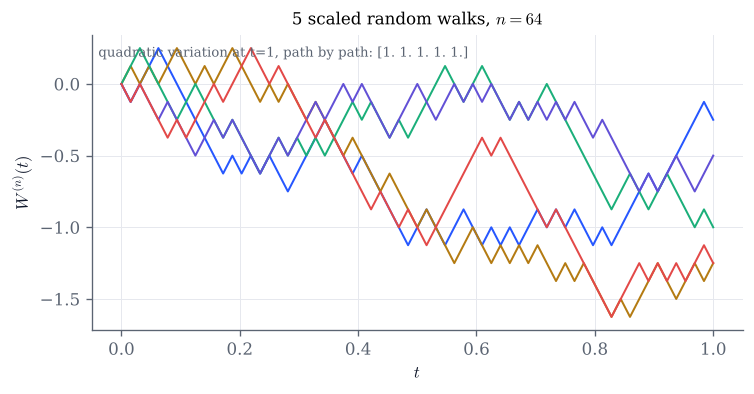

In [2]:
def walks(n=64, n_paths=5, seed=0):
    t, W = scaled_random_walk(n, T=1.0, n_paths=n_paths, seed=seed)
    fig, ax = plt.subplots(figsize=(7, 3.2))
    ax.plot(t, W.T, lw=1.2)
    ax.set(xlabel="$t$", ylabel="$W^{(n)}(t)$", title=f"{n_paths} scaled random walks, $n={n}$")
    qv = p_variation(W, 2)
    ax.text(0.01, 0.96, f"quadratic variation at t=1, path by path: {np.round(qv, 6)}",
            transform=ax.transAxes, va="top", fontsize=8, color=GREY)
    plt.show()

walks()

In [3]:
# Explore: drag n from a handful of coin tosses to thousands of steps per unit of time.
interact(walks,
         n=IntSlider(value=64, min=1, max=4096, step=1, continuous_update=False, description="n"),
         n_paths=IntSlider(value=5, min=1, max=20, continuous_update=False, description="paths"),
         seed=IntSlider(value=0, min=0, max=100, continuous_update=False, description="seed"));

## 2. The central limit theorem at $t=1$

$W^{(n)}(1)$ takes values on the lattice $\{k/\sqrt n\}$ only, yet its histogram approaches the
$\mathcal N(0,1)$ density as $n$ grows (Theorem 5.5 in the notes).

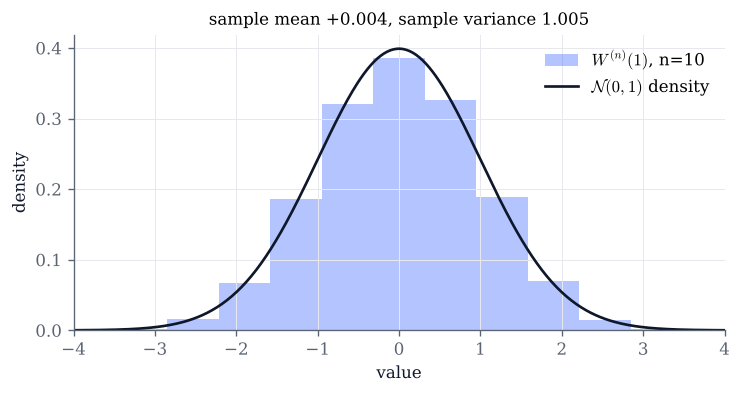

In [4]:
def clt(n=10, n_samples=20_000, seed=1):
    _, W = scaled_random_walk(n, T=1.0, n_paths=n_samples, seed=seed)
    x = W[:, -1]
    fig, ax = plt.subplots(figsize=(7, 3.2))
    width = 2 / np.sqrt(n)                       # lattice spacing of W^(n)(1)
    edges = np.arange(x.min() - width / 2, x.max() + width, width)
    ax.hist(x, bins=edges, density=True, color=COBALT, alpha=0.35, label=f"$W^{{(n)}}(1)$, n={n}")
    grid = np.linspace(-4, 4, 400)
    ax.plot(grid, np.exp(-grid**2 / 2) / np.sqrt(2 * np.pi), color=INK, lw=1.6, label="$\\mathcal{N}(0,1)$ density")
    ax.set(xlim=(-4, 4), xlabel="value", ylabel="density",
           title=f"sample mean {x.mean():+.3f}, sample variance {x.var():.3f}")
    ax.legend()
    plt.show()

clt()

In [5]:
interact(clt,
         n=IntSlider(value=10, min=1, max=1000, continuous_update=False, description="n"),
         n_samples=IntSlider(value=20_000, min=1_000, max=100_000, step=1_000, continuous_update=False, description="samples"),
         seed=IntSlider(value=1, min=0, max=100, continuous_update=False, description="seed"));

## 3. The covariance $\min(s,t)$

A Brownian motion is the centered Gaussian process with $\mathrm{Cov}(W_s,W_t)=\min(s,t)$
(Proposition 5.7, the Gaussian characterization). Below, the covariance estimated from simulated
paths on a grid of times, next to the exact surface.

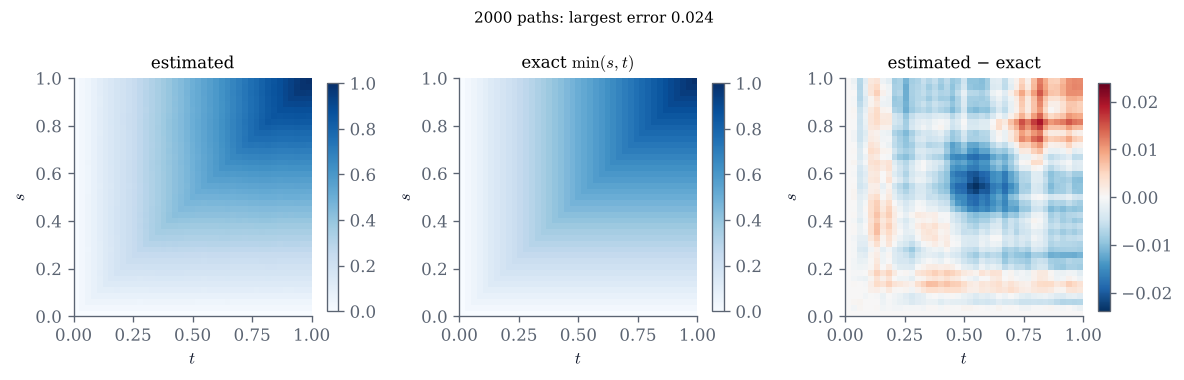

In [6]:
def covariance(n_paths=2_000, seed=2):
    t, W = brownian_paths(T=1.0, n_steps=40, n_paths=n_paths, seed=seed)
    emp = W.T @ W / n_paths                      # E[W_s W_t]; the mean is zero
    exact = np.minimum.outer(t, t)
    fig, axes = plt.subplots(1, 3, figsize=(10, 3.1))
    for ax, M, title in zip(axes, (emp, exact, emp - exact),
                            ("estimated", "exact $\\min(s,t)$", "estimated − exact")):
        lim = 1 if title != "estimated − exact" else max(1e-9, np.abs(emp - exact).max())
        cmap = "Blues" if title != "estimated − exact" else "RdBu_r"
        vmin = 0 if title != "estimated − exact" else -lim
        im = ax.imshow(M, origin="lower", extent=(0, 1, 0, 1), cmap=cmap, vmin=vmin, vmax=lim)
        ax.set(title=title, xlabel="$t$", ylabel="$s$")
        ax.grid(False)
        fig.colorbar(im, ax=ax, shrink=0.8)
    fig.suptitle(f"{n_paths} paths: largest error {np.abs(emp - exact).max():.3f}", fontsize=9)
    fig.tight_layout()
    plt.show()

covariance()

In [7]:
# Explore: the error shrinks like 1/sqrt(number of paths).
interact(covariance,
         n_paths=IntSlider(value=2_000, min=100, max=50_000, step=100, continuous_update=False, description="paths"),
         seed=IntSlider(value=2, min=0, max=100, continuous_update=False, description="seed"));

## 4. Martingales, and a martingale that dies

$W_t$, $W_t^2-t$ and $Z_t=\exp(\sigma W_t-\sigma^2t/2)$ are martingales (Theorem 5.10), so their means
stay at their starting values. $W_t^2$ and $e^{\sigma W_t}$ are not.

The right panel shows individual paths of $Z_t$ over a longer horizon. The exact mean stays at 1, yet almost
every path goes to zero (Remark 5.12). Even the average of 200 paths falls far below 1: the mean is carried by a
few rare paths that become huge, and a sample of 200 almost never contains them.

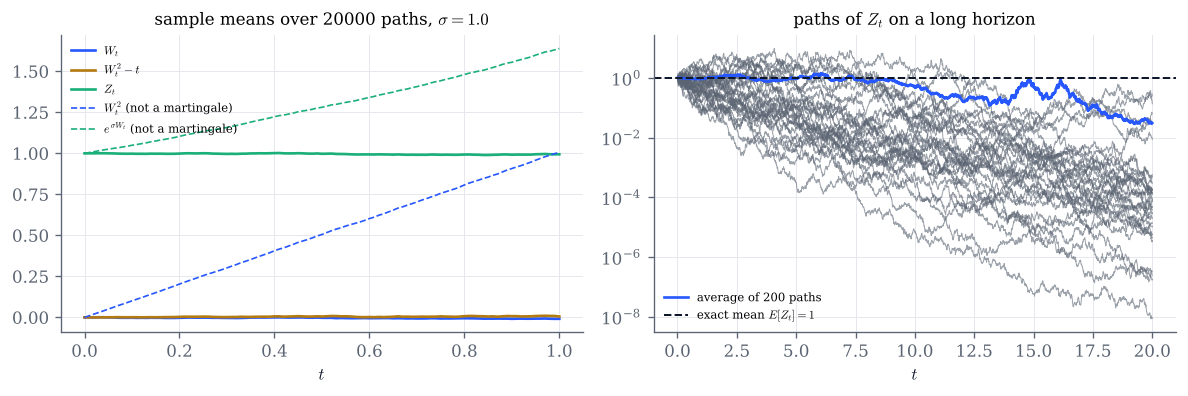

In [8]:
def martingales(sigma=1.0, n_paths=20_000, seed=3):
    t, W = brownian_paths(T=1.0, n_steps=100, n_paths=n_paths, seed=seed)
    fig, (ax, ax2) = plt.subplots(1, 2, figsize=(10, 3.4))
    ax.plot(t, W.mean(0), color=COBALT, label="$W_t$")
    ax.plot(t, (W**2 - t).mean(0), color=GOLD, label="$W_t^2 - t$")
    ax.plot(t, exponential_martingale(t, W, sigma).mean(0), color="#1BAF7A", label="$Z_t$")
    ax.plot(t, (W**2).mean(0), color=COBALT, ls="--", lw=1, label="$W_t^2$ (not a martingale)")
    ax.plot(t, np.exp(sigma * W).mean(0), color="#1BAF7A", ls="--", lw=1, label="$e^{\\sigma W_t}$ (not a martingale)")
    ax.set(xlabel="$t$", title=f"sample means over {n_paths} paths, $\\sigma={sigma}$")
    ax.legend(fontsize=7)

    tl, Wl = brownian_paths(T=20.0, n_steps=2_000, n_paths=200, seed=seed + 1)
    Zl = exponential_martingale(tl, Wl, sigma)
    ax2.plot(tl, Zl[:30].T, color=GREY, lw=0.6, alpha=0.6)
    ax2.plot(tl, Zl.mean(0), color=COBALT, lw=1.6, label="average of 200 paths")
    ax2.axhline(1.0, color=INK, lw=1.2, ls="--", label="exact mean $E[Z_t]=1$")
    ax2.set(yscale="log", xlabel="$t$", title="paths of $Z_t$ on a long horizon")
    ax2.legend(fontsize=7)
    fig.tight_layout()
    plt.show()

martingales()

In [9]:
interact(martingales,
         sigma=FloatSlider(value=1.0, min=0.1, max=2.5, step=0.1, continuous_update=False, description="σ"),
         n_paths=IntSlider(value=20_000, min=1_000, max=100_000, step=1_000, continuous_update=False, description="paths"),
         seed=IntSlider(value=3, min=0, max=100, continuous_update=False, description="seed"));

## 5. Variations along finer and finer partitions

For one Brownian path on $[0,1]$, the $p$-variation $\sum_j |W_{t_{j+1}}-W_{t_j}|^p$ along dyadic partitions
with $n$ intervals. Theorem 5.14: the quadratic variation ($p=2$) converges to $t=1$.
Corollary 5.15: the first variation diverges. Pick any $p$ and see on which side of $2$ it falls.

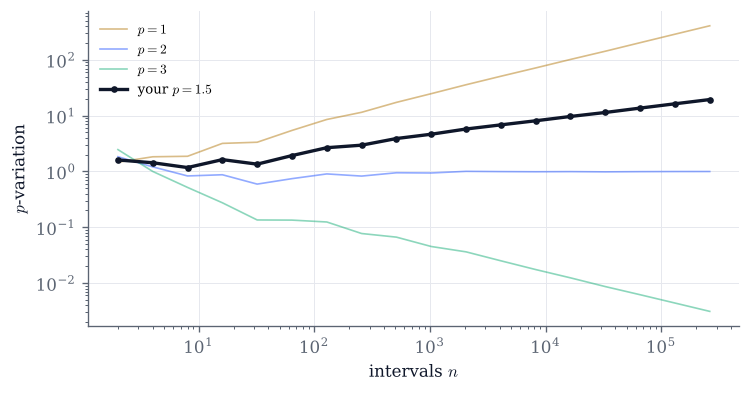

In [10]:
def variations(p=1.5, seed=4):
    K = 18
    _, W = brownian_paths(T=1.0, n_steps=2**K, n_paths=1, seed=seed)
    n = np.array([2**k for k in range(1, K + 1)])
    fig, ax = plt.subplots(figsize=(7, 3.4))
    for q, color in ((1, GOLD), (2, COBALT), (3, "#1BAF7A")):
        v = [p_variation(W[0], q, every=2**(K - k)) for k in range(1, K + 1)]
        ax.plot(n, v, color=color, lw=1, alpha=0.5, label=f"$p={q}$")
    v = [p_variation(W[0], p, every=2**(K - k)) for k in range(1, K + 1)]
    ax.plot(n, v, color=INK, lw=2, marker="o", ms=3, label=f"your $p={p:g}$")
    ax.set(xscale="log", yscale="log", xlabel="intervals $n$", ylabel="$p$-variation")
    ax.legend(fontsize=8)
    plt.show()

variations()

In [11]:
interact(variations,
         p=FloatSlider(value=1.5, min=0.5, max=4.0, step=0.05, continuous_update=False, description="p"),
         seed=IntSlider(value=4, min=0, max=100, continuous_update=False, description="seed"));

## Things to try

- In section 2, take $n=1$, $2$, $3$. Why is the histogram so far from the normal density, and why are some bars empty?
- In section 4, increase $\sigma$. The sample mean of $Z_t$ drifts away from 1 even though $Z$ is a martingale. Why does
  simulation struggle here? (Look at how few paths carry the mean.)
- In section 5, find the value of $p$ at which the curve turns from increasing to decreasing. Does it depend on the seed?